<a href="https://colab.research.google.com/github/Puja528/Uji-Validitas-dan-Realibilitas/blob/main/Analisis_Deskriptif.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Deskriptif per Dimensi
**Topik 1:** Penggunaan AI, Kebiasaan Digital, dan Prokrastinasi Akademik pada Tugas Kuliah

Notebook ini menghitung komposisi jawaban skala 1–5, rerata, standar deviasi, skewness, dan kurtosis untuk lima dimensi, serta membuat grafik komposisi jawaban.

## Impor pustaka

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PATH = "Data_Responden.xlsx"

df = pd.read_excel(PATH)
print("Ukuran data:", df.shape)

Ukuran data: (39, 36)


## Pemetaan skala Likert dan pengelompokan butir ke dimensi

In [3]:
LIKERT = {
    "sangat tidak setuju (sts)": 1,
    "tidak setuju (ts)": 2,
    "netral (n)": 3,
    "setuju (s)": 4,
    "sangat setuju (ss)": 5,
}

DIMENSI = {
    1: ("Penggunaan AI pada Tugas atau Projek Kuliah", r"^penggunaan ai pada tugas"),
    2: ("Aspek Psikologis Penggunaan AI", r"^aspek psikologis"),
    3: ("Kebiasaan Penggunaan Teknologi Digital", r"^kebiasaan penggunaan teknologi"),
    4: ("Prokrastinasi Akademik", r"^prokrastinasi akademik"),
    5: ("Respon Emosional", r"^rsspon emosional|^respon emosional"),
}

data = {}  # {nomor dimensi: DataFrame skor 1-5, kolom D?-B?}
for k, (nama, pola) in DIMENSI.items():
    kolom = [c for c in df.columns if re.search(pola, str(c).strip().lower())]
    skor = df[kolom].apply(lambda s: s.astype(str).str.strip().str.lower().map(LIKERT))
    if skor.isna().any().any():
        raise ValueError(f"Ada jawaban yang tidak terbaca pada Dimensi {k}")
    skor.columns = [f"D{k}-B{i}" for i in range(1, len(kolom) + 1)]
    data[k] = skor
    print(f"Dimensi {k}: {len(kolom)} butir, n = {len(skor)}")

n = len(df)

Dimensi 1: 7 butir, n = 39
Dimensi 2: 7 butir, n = 39
Dimensi 3: 6 butir, n = 39
Dimensi 4: 4 butir, n = 39
Dimensi 5: 5 butir, n = 39


## Galat baku skewness dan kurtosis (untuk uji kemiringan/keruncingan)

In [4]:
se_skew = np.sqrt(6 * n * (n - 1) / ((n - 2) * (n + 1) * (n + 3)))
se_kurt = 2 * se_skew * np.sqrt((n**2 - 1) / ((n - 3) * (n + 5)))
print(f"SE skewness = {se_skew:.3f} | SE kurtosis = {se_kurt:.3f}")
print(f"Batas |skewness| = {1.96*se_skew:.2f} | batas |kurtosis| = {1.96*se_kurt:.2f}")

SE skewness = 0.378 | SE kurtosis = 0.741
Batas |skewness| = 0.74 | batas |kurtosis| = 1.45


## Statistik deskriptif per butir dan per dimensi

In [5]:
def kategori(rerata):
    if rerata <= 1.80: return "sangat rendah"
    if rerata <= 2.60: return "rendah"
    if rerata <= 3.40: return "sedang"
    if rerata <= 4.20: return "tinggi"
    return "sangat tinggi"

tabel = {}
for k, skor in data.items():
    baris = []
    for kode in skor.columns:
        x = skor[kode]
        frek = [int((x == v).sum()) for v in range(1, 6)]
        baris.append({
            "Kode": kode, "1": frek[0], "2": frek[1], "3": frek[2],
            "4": frek[3], "5": frek[4],
            "% Tidak setuju (1-2)": round((frek[0] + frek[1]) / n * 100, 1),
            "% Netral (3)": round(frek[2] / n * 100, 1),
            "% Setuju (4-5)": round((frek[3] + frek[4]) / n * 100, 1),
            "Rerata": x.mean(), "SD": x.std(ddof=1),
            "Skewness": x.skew(), "Kurtosis": x.kurt(),
            "Kategori": kategori(x.mean()),
        })

    rata = skor.mean(axis=1)
    semua = skor.values.ravel()
    frek = [int((semua == v).sum()) for v in range(1, 6)]
    baris.append({
        "Kode": f"Dimensi {k}", "1": frek[0], "2": frek[1], "3": frek[2],
        "4": frek[3], "5": frek[4],
        "% Tidak setuju (1-2)": round((frek[0] + frek[1]) / len(semua) * 100, 1),
        "% Netral (3)": round(frek[2] / len(semua) * 100, 1),
        "% Setuju (4-5)": round((frek[3] + frek[4]) / len(semua) * 100, 1),
        "Rerata": rata.mean(), "SD": rata.std(ddof=1),
        "Skewness": rata.skew(), "Kurtosis": rata.kurt(),
        "Kategori": kategori(rata.mean()),
    })
    tabel[k] = pd.DataFrame(baris).set_index("Kode")

for k, t in tabel.items():
    print(f"\n=== Dimensi {k}: {DIMENSI[k][0]} ===")
    print(t.round(2).to_string())


=== Dimensi 1: Penggunaan AI pada Tugas atau Projek Kuliah ===
            1   2   3    4   5  % Tidak setuju (1-2)  % Netral (3)  % Setuju (4-5)  Rerata    SD  Skewness  Kurtosis       Kategori
Kode                                                                                                                               
D1-B1       0   2   7   18  12                   5.1          17.9            76.9    4.03  0.84     -0.61     -0.06         tinggi
D1-B2       0   0   0   20  19                   0.0           0.0           100.0    4.49  0.51      0.05     -2.11  sangat tinggi
D1-B3       1   3   0   16  19                  10.3           0.0            89.7    4.26  0.99     -1.74      2.97  sangat tinggi
D1-B4       3  11  12   11   2                  35.9          30.8            33.3    2.95  1.05     -0.04     -0.69         sedang
D1-B5       5  11   6   14   3                  41.0          15.4            43.6    2.97  1.22     -0.13     -1.17         sedang
D1-B6       

## Tandai butir/dimensi dengan skewness atau kurtosis di luar +-1,96 x SE

In [6]:
print("\nButir/dimensi yang melampaui batas normalitas:")
for k, t in tabel.items():
    for kode, r in t.iterrows():
        tanda = []
        if abs(r["Skewness"]) > 1.96 * se_skew:
            tanda.append(f"skewness {r['Skewness']:.2f}")
        if abs(r["Kurtosis"]) > 1.96 * se_kurt:
            tanda.append(f"kurtosis {r['Kurtosis']:.2f}")
        if tanda:
            print(f"  {kode}: " + ", ".join(tanda))


Butir/dimensi yang melampaui batas normalitas:
  D1-B2: kurtosis -2.11
  D1-B3: skewness -1.74, kurtosis 2.97
  D1-B6: skewness -1.39, kurtosis 1.85
  D1-B7: skewness -1.52, kurtosis 2.14
  Dimensi 1: kurtosis 1.61
  D2-B4: skewness 0.77
  D2-B6: skewness -1.10
  D3-B2: skewness -0.75
  D3-B3: skewness 0.78
  D3-B6: skewness 0.78
  D4-B2: skewness 0.84
  D5-B1: skewness -1.48, kurtosis 1.88
  D5-B2: skewness -1.40
  D5-B3: skewness -1.05
  D5-B5: skewness -1.62, kurtosis 2.43
  Dimensi 5: skewness -1.52, kurtosis 3.95


## Grafik komposisi jawaban (batang 100%) per dimensi

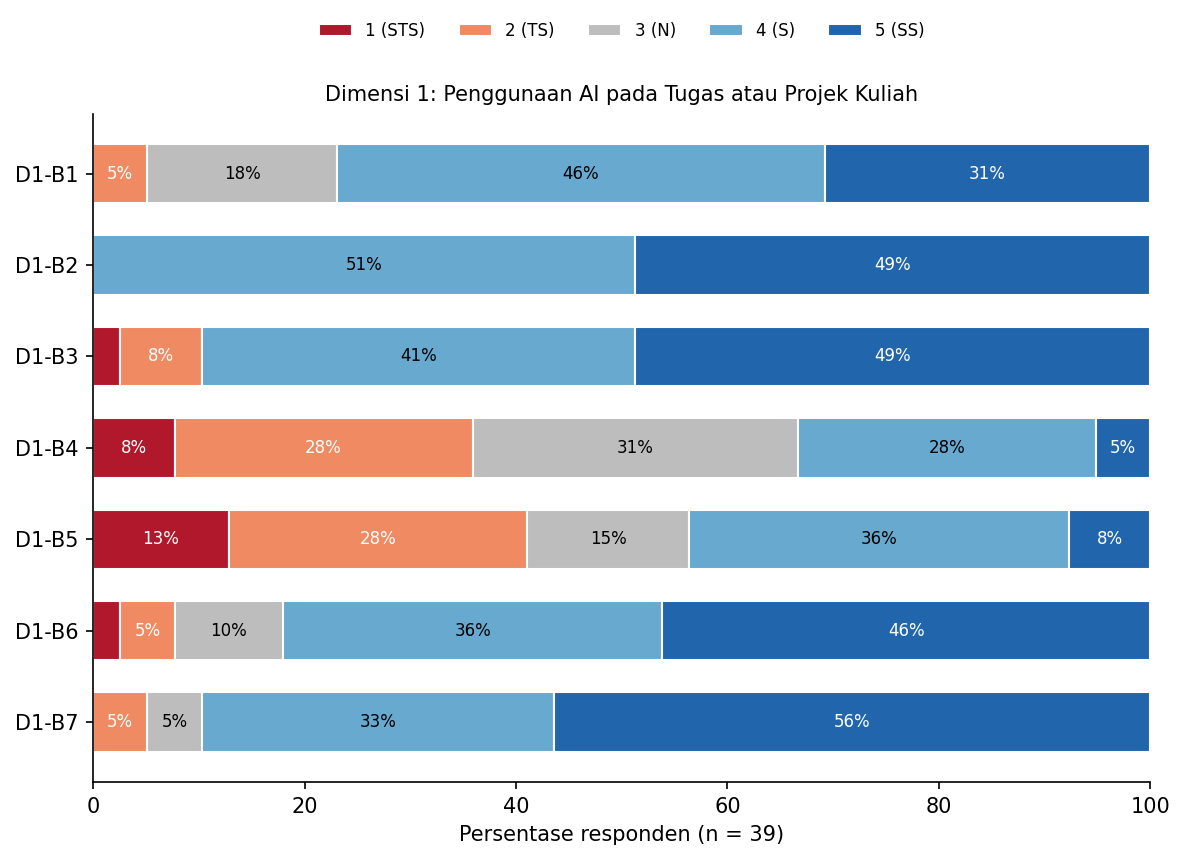

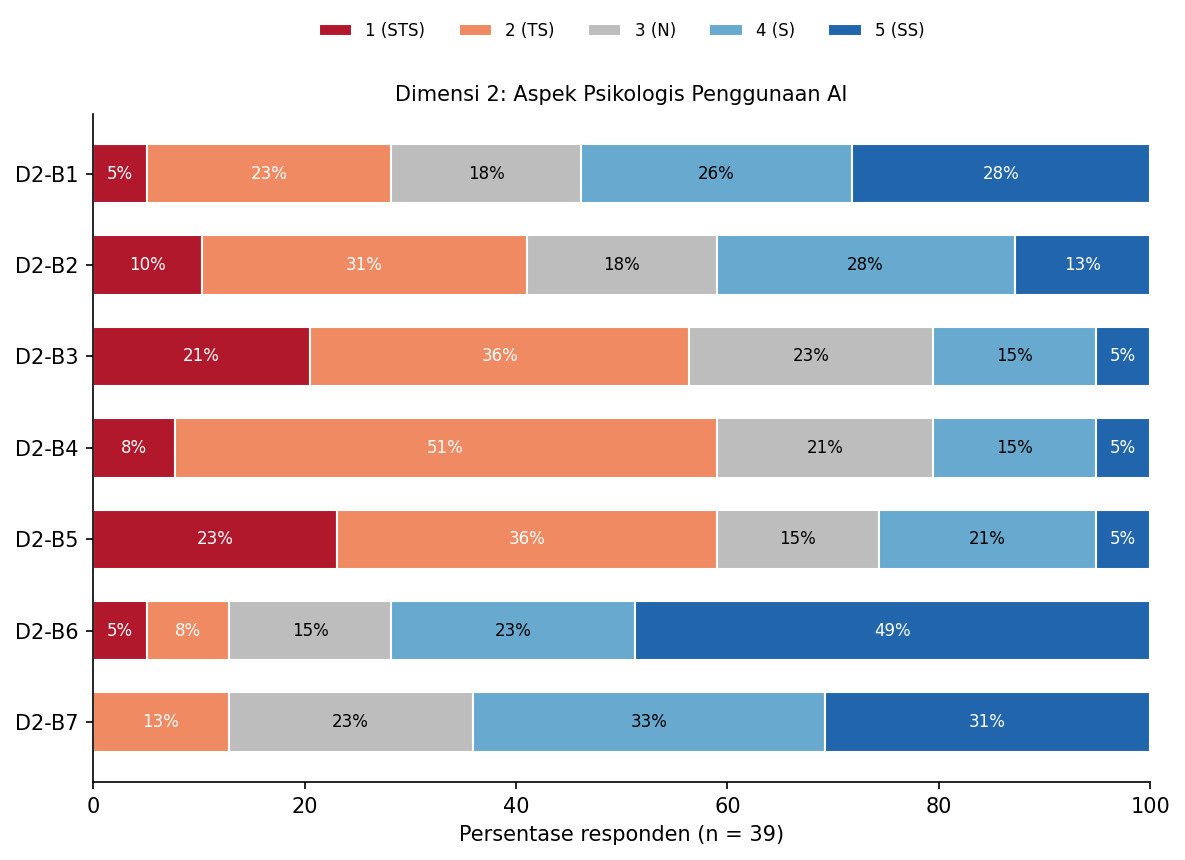

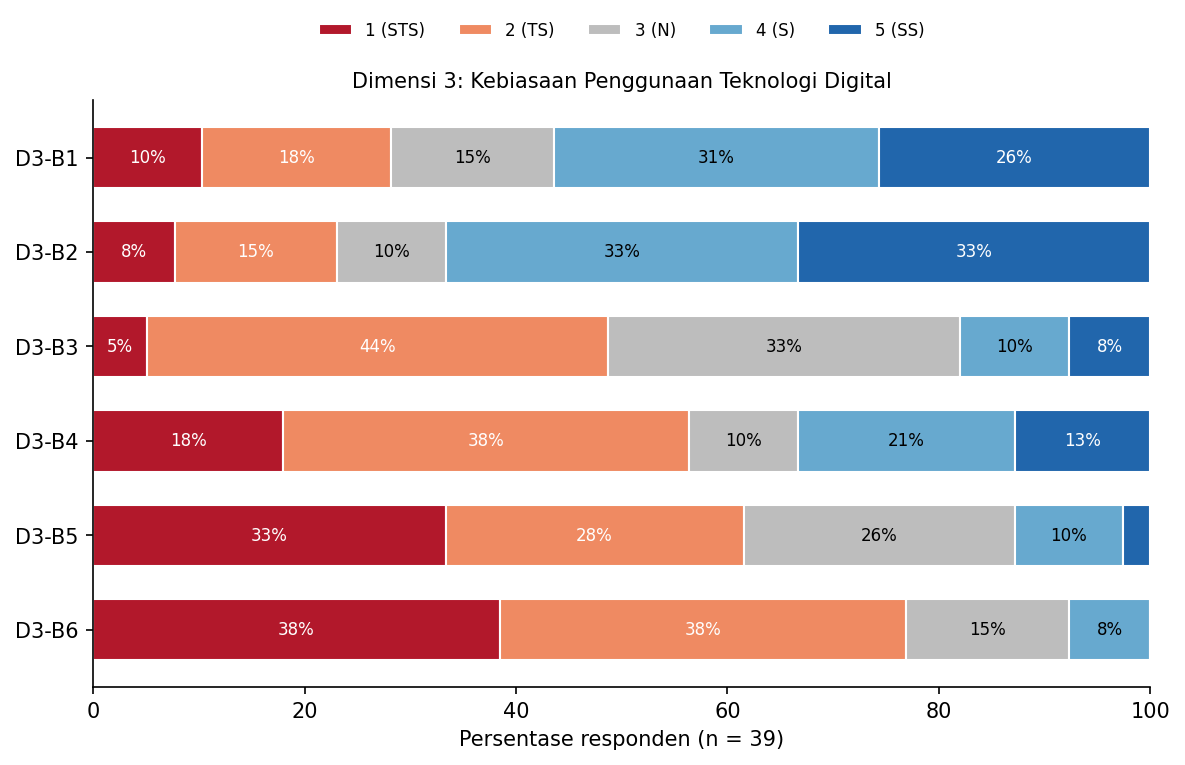

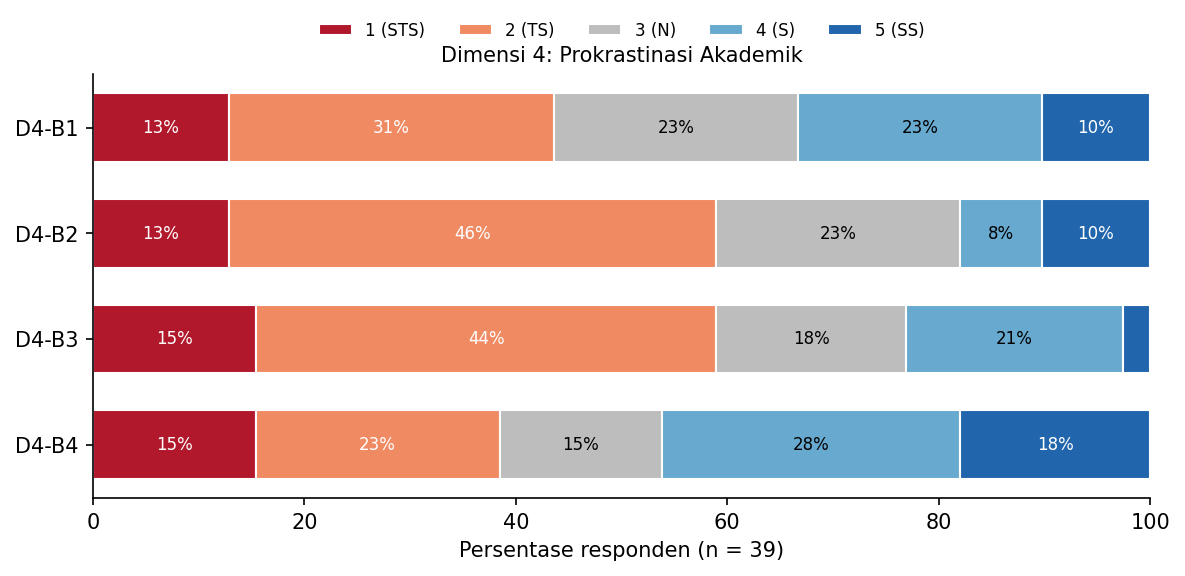

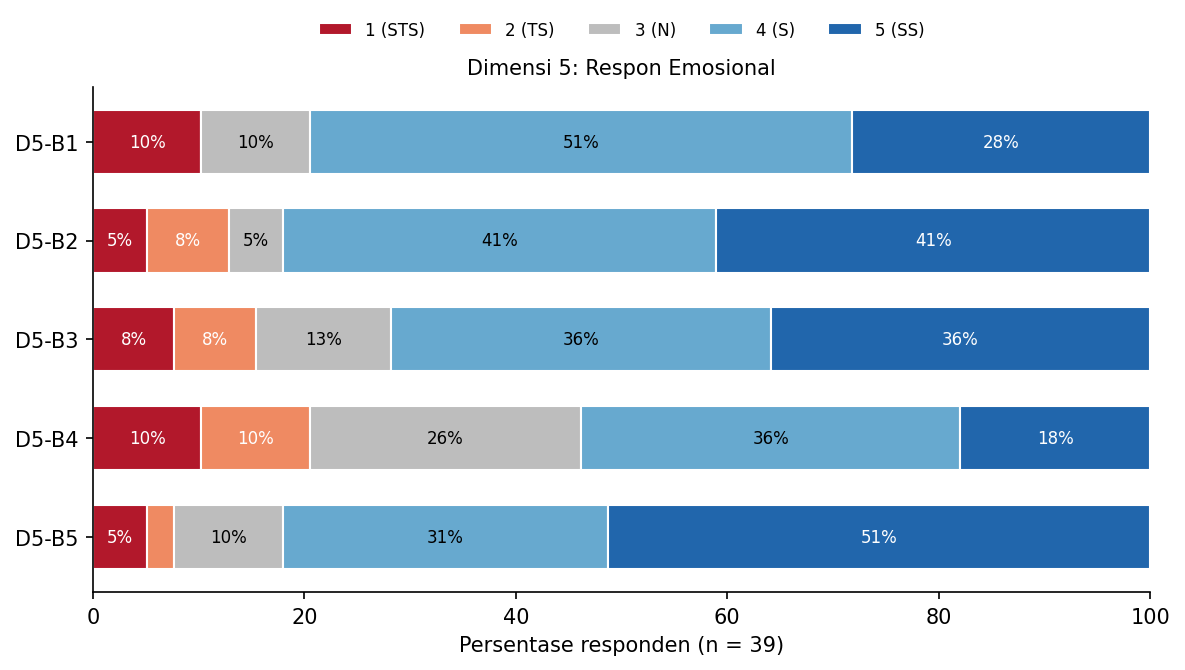

In [7]:
WARNA = ["#B2182B", "#EF8A62", "#BDBDBD", "#67A9CF", "#2166AC"]
LABEL = ["1 (STS)", "2 (TS)", "3 (N)", "4 (S)", "5 (SS)"]

for k, skor in data.items():
    butir = list(skor.columns)[::-1]  # D?-B1 di atas
    fig, ax = plt.subplots(figsize=(8, 0.62 * len(butir) + 1.5), dpi=150)
    kiri = np.zeros(len(butir))
    for v in range(5):
        persen = np.array([(skor[b] == v + 1).mean() * 100 for b in butir])
        ax.barh(butir, persen, left=kiri, color=WARNA[v], label=LABEL[v],
                edgecolor="white", height=0.65)
        for i, p in enumerate(persen):
            if p >= 4.5:
                ax.text(kiri[i] + p / 2, i, f"{p:.0f}%", ha="center", va="center",
                        fontsize=8, color="white" if v in (0, 1, 4) else "black")
        kiri += persen
    ax.set_xlim(0, 100)
    ax.set_xlabel(f"Persentase responden (n = {n})")
    ax.set_title(f"Dimensi {k}: {DIMENSI[k][0]}", fontsize=10)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.0 + 0.16),
              frameon=False, fontsize=8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"komposisi_dimensi_{k}.png")
    plt.show()

## Simpan semua tabel ke satu berkas Excel

In [8]:
with pd.ExcelWriter("statistik_deskriptif.xlsx") as w:
    for k, t in tabel.items():
        t.round(3).to_excel(w, sheet_name=f"Dimensi {k}")
print("Tersimpan: statistik_deskriptif.xlsx dan komposisi_dimensi_1..5.png")

Tersimpan: statistik_deskriptif.xlsx dan komposisi_dimensi_1..5.png
